In [2]:
import os
os.environ["PYTHONHASHSEED"] = str(42)
os.environ["CUDA_VISIBLE_DEVICES"]="0"

import torch
from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, losses, util

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

/tmp/ipykernel_3988259/1666899001.py:6: DeprecationWarning: Importing from 'sentence_transformers.losses' is deprecated and will be removed in a future version. Please use 'sentence_transformers.sentence_transformer.losses' instead.
  from sentence_transformers import SentenceTransformer, SentenceTransformerTrainer, losses, util


## Reconstruct Swedish triplets

Reconstruct triplets as per last cell in `02_translate_msmarco.ipynb`

In [7]:
from collections import defaultdict
from datasets import Dataset

def load(path):
    parts = defaultdict(list)
    with open(path, encoding="utf-8") as f:
        for line in f:
            i, s = line.rstrip("\n").split("\t", 1)
            parts[int(i)].append(s)
    return {i: " ".join(s) for i, s in parts.items()}

def rebuild(prefix, n):
    cols = {c: load(f"translated/translated_{prefix}_{c}.tsv") for c in ["query", "positive", "negative"]}
    keep = [i for i in range(n) if all(i in cols[c] for c in cols)]
    return Dataset.from_dict({c: [cols[c][i] for i in keep] for c in cols})

train_triplets_sv = rebuild("train", 79700)
val_triplets_sv = rebuild("val", 9706)

In [10]:
train_triplets_sv[0]
len(val_triplets_sv)

9706

## Load KB-SBERT

In [13]:
model = SentenceTransformer("KBLab/sentence-bert-swedish-cased")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [13]:
model = SentenceTransformer("KBLab/sentence-bert-swedish-cased")

query = "jobb"
sentences = [
    "arbete",
    "höst",
    "jobbet",
    "jobs"
]

q_emb = model.encode(query, convert_to_tensor=True)
s_emb = model.encode(sentences, convert_to_tensor=True)

scores = util.cos_sim(q_emb, s_emb)[0]   # shape (2,)
for sent, score in zip(sentences, scores):
    print(f"{score:.4f}  {sent}")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

0.9386  arbete
0.3355  höst
0.9357  jobbet
0.9140  jobs


## Loss function

In [14]:
loss = losses.MultipleNegativesRankingLoss(model)

## Train

In [20]:
from sentence_transformers.training_args import BatchSamplers
from sentence_transformers.training_args import SentenceTransformerTrainingArguments

training_args = SentenceTransformerTrainingArguments(
    output_dir="models/kb-sbert-sv-ms-marco-triplets_3e",
    num_train_epochs=3,
    per_device_train_batch_size=64,
    per_device_eval_batch_size=64,
    warmup_steps=0.1,
    learning_rate=2e-5,
    fp16=False,
    bf16=True,
    batch_sampler=BatchSamplers.NO_DUPLICATES,
    seed=42,
    eval_strategy="steps",
    eval_steps=100,
    save_strategy="steps",
    save_steps=100,
    save_total_limit=2,
    logging_steps=100,
    load_best_model_at_end=True,
    report_to="none"
)

In [21]:
from sentence_transformers import SentenceTransformerTrainer

trainer = SentenceTransformerTrainer(
    model=model,
    args=training_args,
    train_dataset=train_triplets_sv,
    eval_dataset=val_triplets_sv,
    loss=loss,
)

In [22]:
trainer.train()
trainer.save_model()

Step,Training Loss,Validation Loss
100,0.475975,0.655422
200,0.242517,0.696631
300,0.234298,0.738263
400,0.241444,0.713150
500,0.269688,0.729548
600,0.309276,0.723952
700,0.348807,0.719345
800,0.413013,0.703191
900,0.462260,0.706951
1000,0.516392,0.692337


[W1102 22:01:21.602412106 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 257949696 bytes (free: 131465216, total: 25338052608).
[W1102 22:01:24.485522543 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 268435456 bytes (free: 22413312, total: 25338052608).
[W1102 22:01:52.921649066 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 287309824 bytes (free: 22413312, total: 25338052608).


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

[W1102 22:02:44.338801689 CUDACachingAllocator.cpp:3934] memory allocation failed with OOM on device 0 while trying to allocate 301989888 bytes (free: 297140224, total: 25338052608).


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (33 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

## Plot training and validation loss

Reading models/kb-sbert-sv-ms-marco-triplets_3e/checkpoint-3738
Saved kb-sbert-sv-ms-marco-triplets_3e_loss.pdf


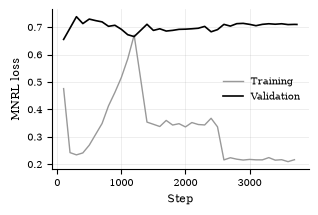

In [4]:
import json, glob
import pandas as pd
import matplotlib.pyplot as plt

run = "models/kb-sbert-sv-ms-marco-triplets_3e"
last = max(glob.glob(f"{run}/checkpoint-*"), key=lambda p: int(p.rsplit("-", 1)[1]))
print("Reading", last)

state = json.load(open(f"{last}/trainer_state.json"))
log = pd.DataFrame(state["log_history"])
train = log.dropna(subset=["loss"])
val = log.dropna(subset=["eval_loss"])

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 8,
    "axes.labelsize": 8,
    "legend.fontsize": 7,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
})

fig, ax = plt.subplots(figsize=(3.03, 2.0))   # ACL column width × height, in inches
ax.plot(train["step"], train["loss"], color="0.6", lw=1, label="Training")
ax.plot(val["step"], val["eval_loss"], color="black", lw=1.2, label="Validation")
ax.set_xlabel("Step")
ax.set_ylabel("MNRL loss")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3, lw=0.5)
fig.tight_layout(pad=0.2)

out = os.path.basename(run) + "_loss.pdf"
fig.savefig(out, bbox_inches="tight")
print("Saved", out)
plt.show()